In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


# Sample Trade — finding an edge, sizing it, and tracking P&L

Structure:
  A. Several ways to find an edge, each producing a numerical estimate q of the
     true probability, compared against the market price p.
  B. Given one chosen edge, decide whether to trade, size with fractional Kelly,
     and simulate the bankroll over repeated plays, using a real price path from
     the database with a hypothetical on top.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from analysis.allocation import kelly_fraction, expected_log_growth
from analysis.correlation import (
    marginal_from_conditionals, joint_from_correlation, frechet_bounds,
)
from db.load import load_market_history

In [ ]:
# Edge from a calibration mispricing

def calibration_q(p, alpha):
    """Favorite-longshot power transform: corrected probability from price p."""
    return p**alpha / (p**alpha + (1 - p)**alpha)

alpha = 1.37            # from earlier fit to historical data
p = 0.20             
q_cal = calibration_q(p, alpha)
print(f"calibration: p={p:.3f}  alpha={alpha}  ->  q={q_cal:.3f}  "
      f"edge={q_cal - p:+.3f}")

calibration: p=0.200  alpha=1.37  ->  q=0.130  edge=-0.070


In [8]:
# Edge from a correlation mispricing

q_corr = marginal_from_conditionals(
    p_a=0.40, p_b_given_a=0.72, p_b_given_not_a=0.43
)["p_b"]
p_corr_market = 0.55
print(f"correlation: derived q={q_corr:.3f}  market p={p_corr_market:.3f}  "
      f"edge={q_corr - p_corr_market:+.3f}")

correlation: derived q=0.546  market p=0.550  edge=-0.004


In [9]:
# --- choose the edge ---
q = q_cal          # calibration-corrected probability
p = 0.20           # market price we'd buy at
spread = 0.03

edge = q - p
enter = abs(edge) > spread
side = "YES" if edge > 0 else "NO"
print(f"q={q:.3f} p={p:.3f} edge={edge:+.3f} spread={spread:.3f} -> "
      f"{'ENTER ' + side if enter else 'NO TRADE'}")

q=0.130 p=0.200 edge=-0.070 spread=0.030 -> ENTER NO


In [10]:
lam = 0.5
f_full = kelly_fraction(q, p)
f_bet = lam * f_full
print(f"full Kelly {f_full:.4f}  ->  half-Kelly bet {f_bet:.4f} "
      f"({f_bet:.1%} of bankroll)")

full Kelly 0.3490  ->  half-Kelly bet 0.1745 (17.5% of bankroll)


2915 snapshots, price range [0.019, 0.421]


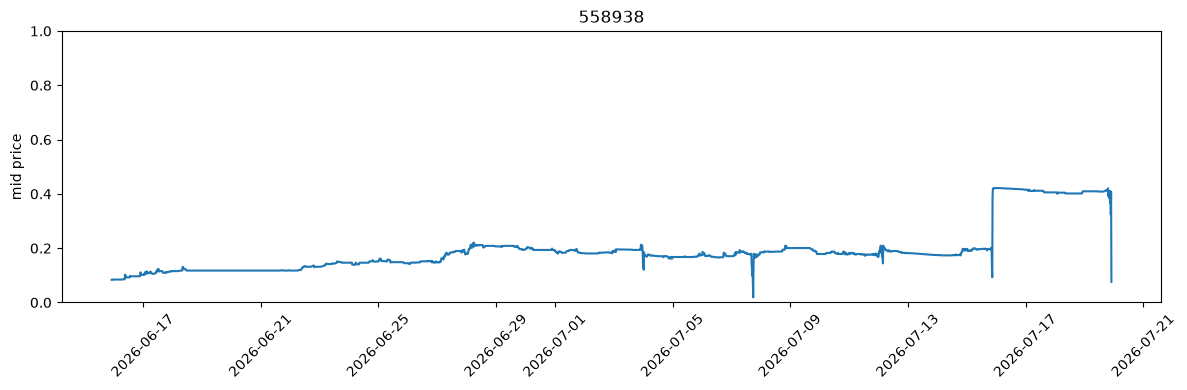

In [12]:
MARKET_ID = "558938"
hist = load_market_history([MARKET_ID])     
if hist.empty:
    print("no history")
else:
    hist = hist.sort_values("snapshot_at")
    print(f"{len(hist)} snapshots, price range "
          f"[{hist['mid_price'].min():.3f}, {hist['mid_price'].max():.3f}]")
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(hist["snapshot_at"], hist["mid_price"], color="C0")
    ax.set_ylim(0, 1); ax.set_ylabel("mid price"); ax.set_title(f"{MARKET_ID}")
    ax.tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()

In [16]:
def simulate(q, p, f, true_prob, n_bets=200, n_paths=2000, seed=0):
    """Final wealth (start 1.0) over n_paths compounding sequences, on the
    side that has the edge. true_prob is the real P(YES)."""
    rng = np.random.default_rng(seed)

    if q >= p:                      # betting YES
        price = p
        win_prob = true_prob
    else:                           # betting NO
        price = 1 - p
        win_prob = 1 - true_prob

    b = (1 - price) / price
    wins = rng.random((n_paths, n_bets)) < win_prob
    mult = np.where(wins, 1 + f * b, 1 - f)
    return mult.prod(axis=1)

true_prob = q      # assume our estimate is correct
finals = simulate(q, p, f_bet, true_prob)      # <-- now passes q, p first
print(f"median final wealth {np.median(finals):.3f}   "
      f"5th pct {np.percentile(finals,5):.3f}   "
      f"lost money {(finals<1).mean():.1%}")

median final wealth 11.519   5th pct 1.765   lost money 1.8%


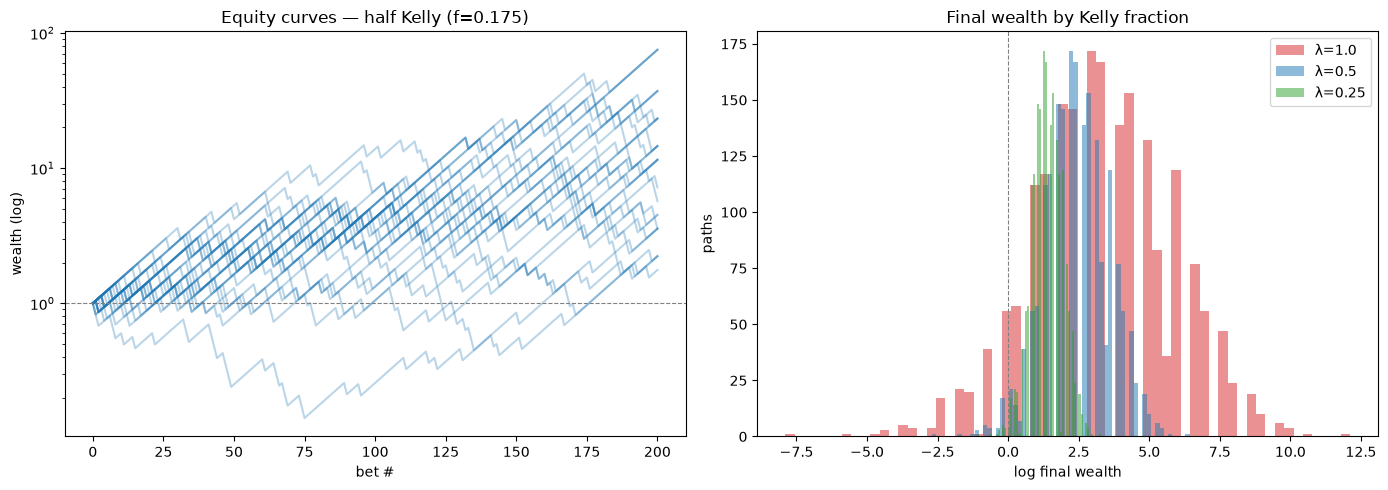

In [17]:
def wealth_paths(q, p, f, true_prob, n_bets=200, n_paths=30, seed=1):
    rng = np.random.default_rng(seed)
    if q >= p:
        price = p; win_prob = true_prob
    else:
        price = 1 - p; win_prob = 1 - true_prob
    b = (1 - price) / price
    wins = rng.random((n_paths, n_bets)) < win_prob
    mult = np.where(wins, 1 + f * b, 1 - f)
    return np.cumprod(np.hstack([np.ones((n_paths, 1)), mult]), axis=1)

paths = wealth_paths(q, p, f_bet, true_prob)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(paths.T, color="C0", alpha=0.3); ax1.axhline(1, color="gray", ls="--", lw=0.8)
ax1.set_yscale("log"); ax1.set_xlabel("bet #"); ax1.set_ylabel("wealth (log)")
ax1.set_title(f"Equity curves — half Kelly (f={f_bet:.3f})")

for lam_i, c in [(1.0, "C3"), (0.5, "C0"), (0.25, "C2")]:
    fin = simulate(q, p, lam_i * f_full, true_prob)
    ax2.hist(np.log(fin), bins=60, alpha=0.5, color=c, label=f"λ={lam_i}")
ax2.axvline(0, color="gray", ls="--", lw=0.8)
ax2.set_xlabel("log final wealth"); ax2.set_ylabel("paths")
ax2.set_title("Final wealth by Kelly fraction"); ax2.legend()
plt.tight_layout(); plt.show()

In [18]:
true_wrong = q - 0.05
for lam_i in (1.0, 0.5, 0.25):
    fin = simulate(q, p, lam_i * f_full, true_wrong)
    print(f"λ={lam_i}: median {np.median(fin):.3f}  "
          f"5th pct {np.percentile(fin,5):.3f}  lost {(fin<1).mean():.1%}")

λ=1.0: median 5035.547  5th pct 231.992  lost 0.1%
λ=0.5: median 120.158  5th pct 29.428  lost 0.1%
λ=0.25: median 12.302  5th pct 6.250  lost 0.0%
